# 03 · Evaluation and Testing

**Goal:** check the model on fires it has never seen, then use it on new data.

- **Input:** `models/fire_risk_model.joblib`, `data/test/test_set.csv` (34 fires)
- **Output:** 3 charts in `reports/figures/`, `reports/submission.csv`

In [1]:
# Libraries used in this notebook
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hide noisy warnings and find the project folders
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
# Tools for charts, calibration and feature importance
import subprocess, joblib
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# Project helpers: labels and the competition score
from src.data import make_labels, TARGET_COLS, TIME_COL, EVENT_COL
from src.model import score, hybrid_scorer, risk_band

# Load the saved model and the untouched test set, then predict
bundle = joblib.load(ROOT / "models" / "fire_risk_model.joblib")
model, FEATURES = bundle["model"], bundle["features"]
test = pd.read_csv(DATA_DIR / "test" / "test_set.csv")
X, y = test[FEATURES], test[TARGET_COLS].to_numpy()
probs = model.predict_proba(X)
labels = make_labels(test[TIME_COL], test[EVENT_COL])

## 1. Competition score on the test set

In [2]:
# Competition scores on the test set, next to the training (CV) score
s = score(probs, test[TIME_COL], test[EVENT_COL])
pd.DataFrame({"Test": [s["hybrid"], s["c_index"], s["brier"]],
              "Training CV": [bundle["cv_hybrid"], None, None]},
             index=["Hybrid score (higher = better)", "C-index (higher = better)", "Brier (lower = better)"]).round(3)

,Test,Training CV
Hybrid score (higher = better),0.971,0.976
C-index (higher = better),0.933,NaN
Brier (lower = better),0.013,NaN


The test score is close to the training score, so the model works on new fires (not just the ones it learned from).

## 2. Right and wrong predictions at 48 h
A fire counts as "predicted hit" if its 48 h risk is 50% or more.

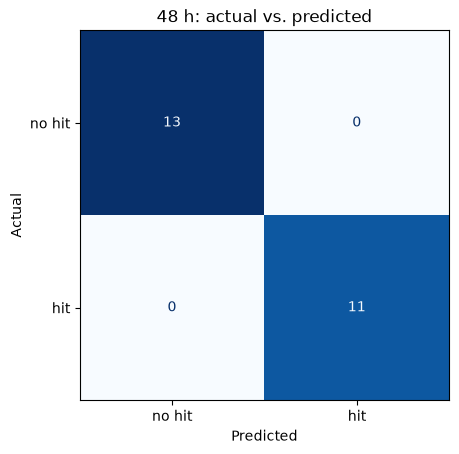

In [3]:
# Confusion matrix at 48 h (skipping fires with an unknown outcome)
known = labels["hit_48h"].notna()
ConfusionMatrixDisplay.from_predictions(labels.loc[known, "hit_48h"].astype(int), (probs[known, 2] >= 0.5).astype(int),
                                        display_labels=["no hit", "hit"], cmap="Blues", colorbar=False)
plt.title("48 h: actual vs. predicted"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig(FIG_DIR / "03_confusion_48h.png", bbox_inches="tight"); plt.show()

## 3. Can we trust the percentages?
If the model says 30%, about 30% of those fires should really hit. Points close to the dashed line = good.

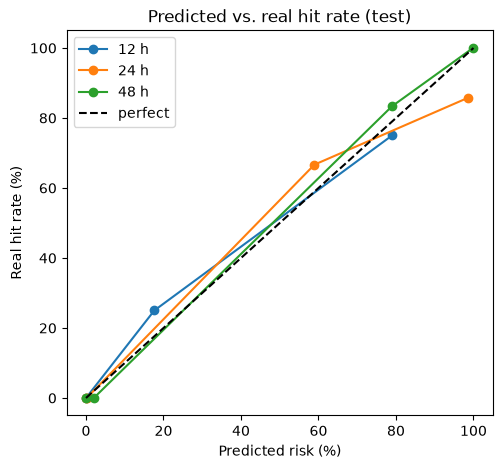

In [4]:
# Calibration: predicted risk vs. how often fires really hit, per time limit
plt.figure(figsize=(5.5, 5))
for k, h in enumerate([12, 24, 48]):
    known = labels[f"hit_{h}h"].notna()
    real, pred = calibration_curve(labels.loc[known, f"hit_{h}h"], probs[known, k], n_bins=4, strategy="quantile")
    plt.plot(pred * 100, real * 100, "o-", label=f"{h} h")
# Dashed line = perfect calibration
plt.plot([0, 100], [0, 100], "k--", label="perfect")
plt.title("Predicted vs. real hit rate (test)")
plt.xlabel("Predicted risk (%)"); plt.ylabel("Real hit rate (%)"); plt.legend()
plt.savefig(FIG_DIR / "03_calibration.png", bbox_inches="tight"); plt.show()

## 4. Which features matter most?
Shuffle one feature at a time: the bigger the score drop, the more important the feature.

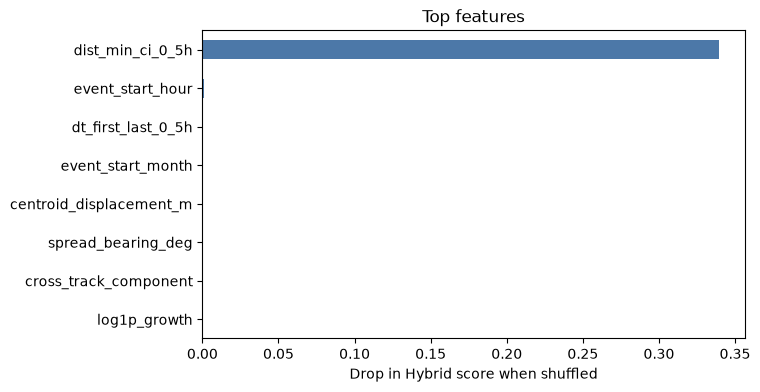

In [5]:
# Shuffle each feature and measure the drop in Hybrid score
imp = permutation_importance(model, X, y, scoring=hybrid_scorer, n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(8)
# Bar chart of the most important features, saved as a PNG
imp.plot.barh(color="#4C78A8", figsize=(7, 4))
plt.title("Top features"); plt.xlabel("Drop in Hybrid score when shuffled")
plt.savefig(FIG_DIR / "03_feature_importance.png", bbox_inches="tight"); plt.show()

Distance to the evacuation zone is by far the most important feature.

## 5. Risk bands (48 h)
Low 0–25% · Medium 25–50% · High 50–75% · Critical 75–100%

In [6]:
# Group test fires into risk bands and count real hits in each band
known = labels["hit_48h"].notna()
bands = pd.DataFrame({"band": risk_band(probs[known, 2] * 100), "hit": labels.loc[known, "hit_48h"].to_numpy()})
bands.groupby("band", observed=False)["hit"].agg(fires="count", real_hits="sum").astype(int)

,fires,real_hits
band,,
Low,13,0
Medium,0,0
High,0,0
Critical,11,11


## 6. Try it on new fires
Take 8 fires from the competition file (no answers) and run `src/predict.py`.

In [7]:
# Pick 8 competition fires from near to far and save them as a sample input
new = pd.read_csv(DATA_DIR / "raw" / "test.csv")
new.sort_values("dist_min_ci_0_5h").iloc[::12].head(8).to_csv(DATA_DIR / "test" / "sample_input.csv", index=False)

# Run the prediction script on the sample, then show the results
subprocess.run([sys.executable, "src/predict.py", "--input", "data/test/sample_input.csv",
                "--output", "data/test/sample_predictions.csv"], cwd=ROOT, check=True)
pd.read_csv(DATA_DIR / "test" / "sample_predictions.csv")[["event_id", "risk_12h_pct", "risk_24h_pct", "risk_48h_pct", "risk_percentage", "risk_band"]]

Saved 8 predictions to data/test/sample_predictions.csv
 event_id  risk_percentage risk_band
 27052376            99.44  Critical
 37196135            98.41  Critical
 54801108            98.08  Critical
 42997746             1.67       Low
 96570675             0.00       Low
 99649465             0.00       Low
 39717591             0.00       Low
 49169401             0.00       Low


,event_id,risk_12h_pct,risk_24h_pct,risk_48h_pct,risk_percentage,risk_band
0,27052376,95.71,98.89,99.44,99.44,Critical
1,37196135,44.17,97.01,98.41,98.41,Critical
2,54801108,85.00,92.46,98.08,98.08,Critical
3,42997746,1.67,1.67,1.67,1.67,Low
4,96570675,0.00,0.00,0.00,0.00,Low
5,99649465,0.00,0.00,0.00,0.00,Low
6,39717591,0.00,0.00,0.00,0.00,Low
7,49169401,0.00,0.00,0.00,0.00,Low


Create the competition submission for all 95 fires:

In [8]:
# Predict all competition fires and write the submission file
subprocess.run([sys.executable, "src/predict.py", "--input", "data/raw/test.csv", "--output", "reports/test_predictions.csv",
                "--submission", "reports/submission.csv"], cwd=ROOT, check=True, capture_output=True)
pd.read_csv(ROOT / "reports" / "submission.csv").head()

,event_id,prob_12h,prob_24h,prob_48h,prob_72h
0,10662602,0.0000,0.0000,0.0000,0.9833
1,13353600,0.6027,0.9966,0.9970,0.9978
2,13942327,0.0000,0.0000,0.0000,0.9833
3,16112781,0.7441,0.9852,0.9970,0.9985
4,17132808,0.0161,0.0161,0.0161,0.9835


## Summary
**Good**
- High Hybrid score on unseen fires.
- The percentages are reliable (close to the dashed line).

**Not so good**
- Weaker at telling *when* a fire hits (early vs. late).
- Depends almost only on distance.
- The 72 h value (about 98% for all fires) is a scoring side effect. Use the 12/24/48 h values for decisions.

**Limits:** only 221 fires in total; no weather, wind or terrain data.